In [1]:
import spacy
nlp = spacy.load("xx_ent_wiki_sm")
doc = nlp("Mahasiswa belajar Natural Language Processing.")
for token in doc:
    print(f"{token.text:<15} {token.pos_:<10} {token.dep_}")
#
doc = nlp("Mahasiswa belajar Natural Language Processing.")
print(f"{'Token':<15} {'POS':<10} {'Lemma'}")
print("-" * 40)
for token in doc:
    print(f"{token.text:<15} {token.pos_:<10} {token.lemma_}")
#
import pandas as pd
def analyze_pos(text, nlp_model):
    doc = nlp_model(text)
    results = []
    for token in doc:
        results.append({
            "Token": token.text,
            "POS": token.pos_,
            "POS Tag": token.tag_,
            "Lemma": token.lemma_,
            "Dependency": token.dep_,
            "Head": token.head.text
        })
    return pd.DataFrame(results)
df_pos = analyze_pos("Mahasiswa belajar NLP.", nlp)
print(df_pos.to_string(index=False))
#
sentences = [
    "Mahasiswa belajar NLP.",
    "Dosen mengajar Natural Language Processing.",
    "Mahasiswa membaca buku.",
    "Sistem memproses data teks.",
    "Model bahasa memprediksi kata berikutnya."
]
for sentence in sentences:
    print(f"\nKalimat: {sentence}")
    df_result = analyze_pos(sentence, nlp)
    print(df_result[["Token", "POS", "Dependency", "Head"]].to_string(index=False))
    print()
#
doc = nlp("Mahasiswa belajar NLP.")
print(f"{'Token':<15} {'Dep':<12} {'Head'}")
print("-" * 40)
for token in doc:
    print(f"{token.text:<15} {token.dep_:<12} {token.head.text}")

Mahasiswa                  
belajar                    
Natural                    
Language                   
Processing                 
.                          
Token           POS        Lemma
----------------------------------------
Mahasiswa                  
belajar                    
Natural                    
Language                   
Processing                 
.                          
    Token POS POS Tag Lemma Dependency      Head
Mahasiswa                              Mahasiswa
  belajar                                belajar
      NLP                                    NLP
        .                                      .

Kalimat: Mahasiswa belajar NLP.
    Token POS Dependency      Head
Mahasiswa                Mahasiswa
  belajar                  belajar
      NLP                      NLP
        .                        .


Kalimat: Dosen mengajar Natural Language Processing.
     Token POS Dependency       Head
     Dosen                     Dosen
  mengaj

In [ ]:
import pandas as pd
df = pd.read_csv('IndoLeX_Database_preprocessed.csv')
text_column = "processed_text"
sample = df.sample(10, random_state=42)
for _, row in sample.iterrows():
    text = str(row[text_column])[:200]  # batasi panjang
    doc = nlp(text)
    pos_counts = {}
    for token in doc:
        pos = token.pos_
        pos_counts[pos] = pos_counts.get(pos, 0) + 1
    print(f"Teks: {text[:80]}...")
    print(f"POS Distribution: {pos_counts}")
    print()

informal_texts = [
    "aku lg belajar NLP nih",
    "gue udah baca buku itu",
    "modelnya bagus bgt sih",
    "nggak ngerti sama sekali",
    "udah instal belum?"
]
print("Analisis Teks Informal:")
print("=" * 60)
for text in informal_texts:
    doc = nlp(text)
    print(f"\nTeks: {text}")
    for token in doc:
        print(f"  {token.text:<15} {token.pos_}")

Teks: kbbiderived...
POS Distribution: {'': 1}

Teks: kbbidirect...
POS Distribution: {'': 1}

Teks: kbbiderived...
POS Distribution: {'': 1}

Teks: kbbidirect...
POS Distribution: {'': 1}

Teks: kbbidirect...
POS Distribution: {'': 1}

Teks: kbbiderived...
POS Distribution: {'': 1}

Teks: kbbidirect...
POS Distribution: {'': 1}

Teks: kbbidirect...
POS Distribution: {'': 1}

Teks: kbbiderived...
POS Distribution: {'': 1}

Teks: kbbiderived...
POS Distribution: {'': 1}

Analisis Teks Informal:

Teks: aku lg belajar NLP nih
  aku             
  lg              
  belajar         
  NLP             
  nih             

Teks: gue udah baca buku itu
  gue             
  udah            
  baca            
  buku            
  itu             

Teks: modelnya bagus bgt sih
  modelnya        
  bagus           
  bgt             
  sih             

Teks: nggak ngerti sama sekali
  nggak           
  ngerti          
  sama            
  sekali          

Teks: udah instal belum?
  udah     

In [2]:
import spacy
from spacy import displacy
from IPython.display import HTML, display

nlp = spacy.load("xx_ent_wiki_sm")
doc = nlp("Mahasiswa belajar Natural Language Processing.")
html = displacy.render(
    doc,
    style="dep",
    jupyter=False,
    options={"distance": 90}
)
display(HTML(html))
with open("dependency_tree.html", "w", encoding="utf-8") as f:
    f.write(html)

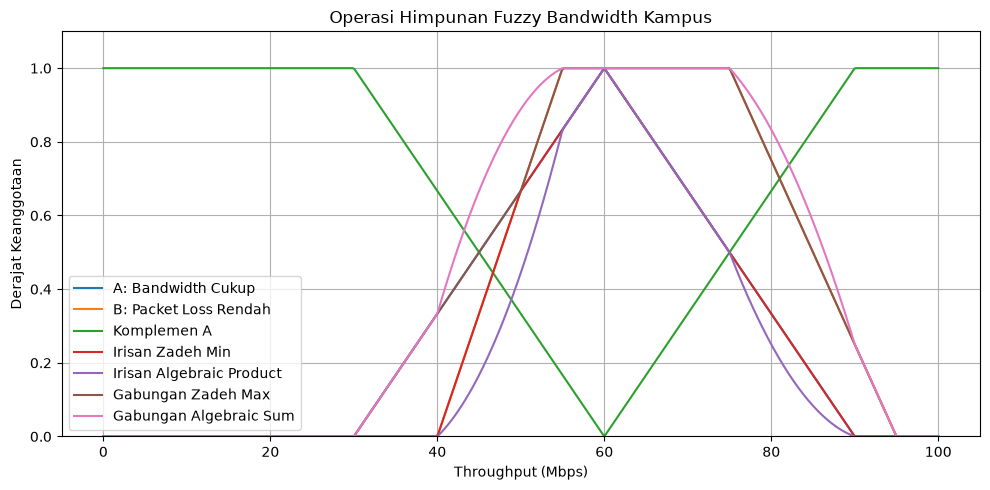

 Throughput     A     B   Min  Product   Max  Alg. Sum  Komplemen A
         35 0.167 0.000 0.000    0.000 0.167     0.167        0.833
         50 0.667 0.667 0.667    0.444 0.667     0.889        0.333
         65 0.833 1.000 0.833    0.833 1.000     1.000        0.167
         80 0.333 0.750 0.333    0.250 0.750     0.833        0.667


In [3]:
# tugas analisis linguistik

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

# Semesta pembicaraan
x = np.linspace(0, 100, 500)

# Fungsi keanggotaan A: Segitiga [30, 60, 90]
def fungsi_a(x):
    return np.maximum(
        0,
        np.minimum((x - 30) / 30, (90 - x) / 30)
    )

# Fungsi keanggotaan B: Trapesium [40, 55, 75, 95]
def fungsi_b(x):
    return np.maximum(
        0,
        np.minimum(
            np.minimum((x - 40) / 15, 1),
            (95 - x) / 20
        )
    )

# Fungsi operasi fuzzy
def zadeh_min(a, b):
    return np.minimum(a, b)

def algebraic_product(a, b):
    return a * b

def zadeh_max(a, b):
    return np.maximum(a, b)

def algebraic_sum(a, b):
    return a + b - (a * b)

def komplemen_a(a):
    return 1 - a

# Menghitung fungsi keanggotaan
mu_a = fungsi_a(x)
mu_b = fungsi_b(x)

# Membuat grafik
plt.figure(figsize=(10, 5))
plt.plot(x, mu_a, label="A: Bandwidth Cukup")
plt.plot(x, mu_b, label="B: Packet Loss Rendah")
plt.plot(x, komplemen_a(mu_a), label="Komplemen A")
plt.plot(x, zadeh_min(mu_a, mu_b), label="Irisan Zadeh Min")
plt.plot(x, algebraic_product(mu_a, mu_b),
         label="Irisan Algebraic Product")
plt.plot(x, zadeh_max(mu_a, mu_b), label="Gabungan Zadeh Max")
plt.plot(x, algebraic_sum(mu_a, mu_b),
         label="Gabungan Algebraic Sum")

plt.title("Operasi Himpunan Fuzzy Bandwidth Kampus")
plt.xlabel("Throughput (Mbps)")
plt.ylabel("Derajat Keanggotaan")
plt.ylim(0, 1.1)
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

# Pengujian pada empat nilai throughput
data_uji = [35, 50, 65, 80]
hasil = []

for nilai in data_uji:
    a = float(fungsi_a(nilai))
    b = float(fungsi_b(nilai))

    hasil.append({
        "Throughput": nilai,
        "A": round(a, 3),
        "B": round(b, 3),
        "Min": round(float(zadeh_min(a, b)), 3),
        "Product": round(float(algebraic_product(a, b)), 3),
        "Max": round(float(zadeh_max(a, b)), 3),
        "Alg. Sum": round(float(algebraic_sum(a, b)), 3),
        "Komplemen A": round(float(komplemen_a(a)), 3)
    })

tabel_hasil = pd.DataFrame(hasil)
print(tabel_hasil.to_string(index=False))
